# 03 · EDA Capa Gold: Tablas Agregadas, Hipótesis (H1–H4), Modelo Temporal y Paridad
**Proyecto:** VIGÍA-VIH Medellín (2012–2023)  
**Arquitectura Medallion:** Capa `Gold` (`data/gold/*.csv` y `data/gold/*.json`)  
**Autora:** Claudia Andrea Cifuentes Hincapié  

---
### Reglas Analíticas e Inferenciales de la Capa `Gold` (`src/analitica.py` y `src/modelo.py`)
1. **Regla 8 (Protección de Celdas Pequeñas e Intervalos de Wilson):**
   - Todo estrato con $n < 10$ (`MIN_CELDA = 10`) se marca como `suprimido = True` y no expone porcentajes en el tablero.
   - Los intervalos de confianza del 95% se calculan mediante la fórmula cuadrática exacta de **Wilson** ($z = 1,96$).
2. **Regla 9 (Modelos Logísticos Multivariables por IRLS y Pruebas H1–H3):**
   - **Modelo A (`regresion_principal.csv`):** Ajusta `anio_c` ($	ext{año} - 2012$), `sexo` (ref: Hombre), `grupo_edad` (ref: 18–28), `aseguramiento` (ref: Contributivo) y `mecanismo` (ref: Heterosexual). Evalúa **H1** (tendencia anual) y **H3** (edad $\ge 40$ y aseguramiento subsidiado/no asegurado).
   - **Modelo B (`regresion_comuna.csv`):** Añade el bloque de 20 comunas (ref: `10 La Candelaria`) en los registros con comuna conocida ($n = 11.509$) y ejecuta la Prueba de Razón de Verosimilitud (**H2**: $\chi^2(19)=22,64, p=0,2534$).
3. **Regla 10 (Prevención de Fuga de Datos y Validación Temporal 2012–2018 $\rightarrow$ 2019–2023 — H4):**
   - Se excluyen por circularidad/fuga: `hospitalizado`, `n_oportunistas`, `fallecido` y `anio`.
   - Entrenamiento en `2012–2018` ($n=7.249$, prevalencia $14,3\%$) y prueba temporal en `2019–2023` ($n=7.337$, prevalencia $6,2\%$), con IC95 por bootstrap pareado ($B=500$, `SEED=2026`).

In [1]:
import sys
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = PROJ_ROOT_OVERRIDE if "PROJ_ROOT_OVERRIDE" in globals() else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config

# Lectura de las tablas Gold oficiales (sin alterar los archivos que consume app.py)
serie = pd.read_csv(config.DIR_GOLD / "serie_anual.csv")
perf = pd.read_csv(config.DIR_GOLD / "perfil_tardio.csv")
terr = pd.read_csv(config.DIR_GOLD / "territorio_comuna.csv")
reg_a = pd.read_csv(config.DIR_GOLD / "regresion_principal.csv")
sens = pd.read_csv(config.DIR_GOLD / "sensibilidad_tendencia.csv")
mod_comp = pd.read_csv(config.DIR_GOLD / "modelos_comparacion.csv")
cal_mod = pd.read_csv(config.DIR_GOLD / "calibracion_modelo.csv")
deriva = pd.read_csv(config.DIR_GOLD / "deriva_temporal.csv")
imp_var = pd.read_csv(config.DIR_GOLD / "importancia_variables.csv")
hipotesis = pd.read_csv(config.DIR_GOLD / "hipotesis.csv")
kpis = json.loads((config.DIR_GOLD / "kpis.json").read_text(encoding="utf-8"))
res_est = json.loads((config.DIR_GOLD / "resumen_estadistico.json").read_text(encoding="utf-8"))

print("=== KPIs OFICIALES EN GOLD (kpis.json) ===")
print(json.dumps(kpis, indent=2, ensure_ascii=False))

=== KPIs OFICIALES EN GOLD (kpis.json) ===
{
  "notificaciones": 15470,
  "personas": 14881,
  "poblacion_analisis": 14586,
  "pct_tardio_global": 10.222130810366105,
  "pct_tardio_primer_anio": 22.13622291021672,
  "primer_anio": 2012,
  "pct_tardio_ultimo_anio_completo": 5.99208592425099,
  "ultimo_anio_completo": 2022,
  "pct_mujeres": 15.172082819141645,
  "mediana_edad": 30.0,
  "pct_sin_comuna": 21.1,
  "fecha_min": "2012-01-02",
  "fecha_max": "2023-07-19",
  "anio_parcial": 2023,
  "pct_personas_renotificadas": 3.823667764263154,
  "pct_hospitalizados_vih": 14.417716685757922,
  "pct_hospitalizados_sida": 65.86538461538461,
  "pct_con_oportunista_sida": 90.625,
  "pct_con_oportunista_vih": 0.15273004963726614,
  "mediana_dias_consulta_notif": 3.0
}


### 1. Veredicto de las Cuatro Hipótesis (`hipotesis.csv`)

In [2]:
display(hipotesis[["id", "veredicto", "enunciado", "resultado"]])

,id,veredicto,enunciado,resultado
0,H1,Se sostiene,La proporción de presentación avanzada (SIDA o...,OR/año = 0.862 (IC95 0.847–0.878); solo 2012-2...
1,H2,No se sostiene,La presentación avanzada varía entre comunas m...,LRT χ²(19) = 22.6; p = 0.2534. Descriptivo: χ²...
2,H3,Se sostiene,La edad ≥ 40 años y no estar en régimen contri...,40-49 años: OR 3.32 (2.79–3.96); 50-59 años: O...
3,H4,Se sostiene en discriminación; no en calibraci...,"Con variables disponibles al notificar, un mod...",(a) AUC 0.724 (IC95 0.701–0.750): cumple. (b) ...


### 2. Resultados Inferenciales: Tendencia Anual (`H1`), Sensibilidades y Determinantes (`H3`)

In [3]:
print("Serie Anual (2012-2023):")
display(serie[["anio", "n", "n_tardio", "pct_tardio", "ic_inf", "ic_sup", "anio_parcial"]].round(2))

print("\nAnálisis de Sensibilidad de la Tendencia Anual (H1):")
display(sens.round(4))

print("\nModelo A - Regresión Logística Multivariable IRLS (H3):")
display(reg_a.round(4))

Serie Anual (2012-2023):


,anio,n,n_tardio,pct_tardio,ic_inf,ic_sup,anio_parcial
0,2012,646,143,22.14,19.10,25.50,False
1,2013,668,123,18.41,15.66,21.53,False
2,2014,797,139,17.44,14.96,20.23,False
3,2015,1004,140,13.94,11.94,16.22,False
4,2016,1139,145,12.73,10.92,14.79,False
5,2017,1374,169,12.30,10.67,14.14,False
6,2018,1621,179,11.04,9.61,12.66,False
7,2019,1610,124,7.70,6.50,9.11,False
8,2020,1349,99,7.34,6.07,8.85,False
9,2021,1739,85,4.89,3.97,6.00,False



Análisis de Sensibilidad de la Tendencia Anual (H1):


,analisis,OR_por_anio,IC95_inf,IC95_sup,p,n,eventos
0,Crudo (solo año),0.8510,0.8363,0.8659,0.0000,14586,1491
1,Ajustado (modelo principal),0.8625,0.8472,0.8780,0.0000,14583,1489
2,"Ajustado, sin 2023 (año parcial)",0.8650,0.8488,0.8815,0.0000,13714,1451
3,"Ajustado, solo notificación rutinaria + sin da...",0.8724,0.8565,0.8887,0.0000,13048,1422
4,"Ajustado, solo notificación rutinaria",0.8707,0.8200,0.9245,0.0000,7003,488
5,"Ajustado, resultado = solo SIDA (excluye 'Muer...",0.8578,0.8415,0.8744,0.0000,14340,1246
6,"Ajustado, solo 2012-2018",0.9146,0.8832,0.9471,0.0000,7247,1037
7,"Ajustado, solo 2019 en adelante",0.8642,0.8017,0.9315,0.0001,7336,452



Modelo A - Regresión Logística Multivariable IRLS (H3):


,termino,OR,IC95_inf,IC95_sup,p,modelo
0,anio_c,0.8625,0.8472,0.8780,0.0000,A: año + sexo + edad + aseguramiento + mecanismo
1,sexo: Mujer,0.7384,0.6331,0.8612,0.0001,A: año + sexo + edad + aseguramiento + mecanismo
2,grupo_edad: 29-39,2.2274,1.9127,2.5939,0.0000,A: año + sexo + edad + aseguramiento + mecanismo
3,grupo_edad: 40-49,3.3241,2.7892,3.9616,0.0000,A: año + sexo + edad + aseguramiento + mecanismo
4,grupo_edad: 50-59,3.8253,3.1518,4.6426,0.0000,A: año + sexo + edad + aseguramiento + mecanismo
5,grupo_edad: 60+,4.3447,3.3929,5.5635,0.0000,A: año + sexo + edad + aseguramiento + mecanismo
6,grupo_edad: <18,0.5104,0.2368,1.1004,0.0862,A: año + sexo + edad + aseguramiento + mecanismo
7,aseguramiento: Especial/Excepción,0.9940,0.6832,1.4462,0.9748,A: año + sexo + edad + aseguramiento + mecanismo
8,aseguramiento: Indeterminado,0.7479,0.3250,1.7208,0.4944,A: año + sexo + edad + aseguramiento + mecanismo
9,aseguramiento: No asegurado,2.5369,2.1123,3.0468,0.0000,A: año + sexo + edad + aseguramiento + mecanismo


### 3. Evaluación del Modelo Predictivo en Prueba Temporal 2019–2023 (`H4`)

,modelo,auc,auc_inf,auc_sup,pr_auc,lift_top20,recall_top20,brier,cal_pendiente,cal_intercepto
0,Prevalencia (sin modelo),0.498,0.472,0.523,0.061,0.905,0.181,0.065,NaN,NaN
1,Regla: edad ≥ 40 años,0.610,0.588,0.634,0.087,1.964,0.393,0.224,NaN,NaN
2,Regresión logística: solo edad,0.682,0.659,0.707,0.120,1.964,0.393,0.064,1.033,-0.861
3,Regresión logística (modelo primario),0.724,0.701,0.750,0.156,2.427,0.486,0.063,1.036,-0.889
4,Gradient boosting (comparador),0.725,0.703,0.750,0.155,2.438,0.488,0.063,1.064,-0.860



Importancia de Variables por Permutación (Caída de AUC en Prueba Temporal):


,variable,caida_auc,sd
0,edad_anios,0.1070,0.0086
1,aseguramiento,0.0477,0.0052
2,mecanismo,0.0388,0.0041
3,zona,0.0010,0.0012
4,sexo,0.0009,0.0014
5,comuna,-0.0034,0.0037


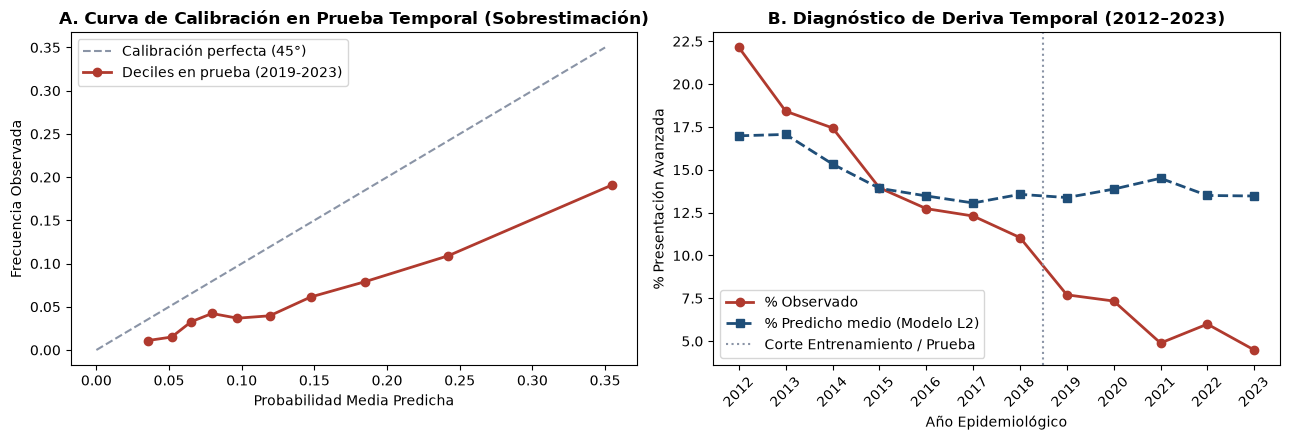

In [4]:
cols_m = ["modelo", "auc", "auc_inf", "auc_sup", "pr_auc", "lift_top20", "recall_top20", "brier", "cal_pendiente", "cal_intercepto"]
display(mod_comp[cols_m].round(3))

print("\nImportancia de Variables por Permutación (Caída de AUC en Prueba Temporal):")
display(imp_var.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# Panel A: Calibración por deciles
axes[0].plot([0, 0.35], [0, 0.35], "--", color="#8A94A6", label="Calibración perfecta (45°)")
axes[0].plot(cal_mod["pred_media"], cal_mod["obs"], "o-", color="#B03A2E", linewidth=2, label="Deciles en prueba (2019-2023)")
axes[0].set_title("A. Curva de Calibración en Prueba Temporal (Sobrestimación)", fontweight="bold")
axes[0].set_xlabel("Probabilidad Media Predicha")
axes[0].set_ylabel("Frecuencia Observada")
axes[0].legend()

# Panel B: Deriva temporal
axes[1].plot(deriva["anio"], deriva["observado"] * 100, "o-", color="#B03A2E", linewidth=2, label="% Observado")
axes[1].plot(deriva["anio"], deriva["predicho_medio"] * 100, "s--", color="#1F4E78", linewidth=2, label="% Predicho medio (Modelo L2)")
axes[1].axvline(2018.5, color="#8A94A6", linestyle=":", linewidth=1.5, label="Corte Entrenamiento / Prueba")
axes[1].set_title("B. Diagnóstico de Deriva Temporal (2012–2023)", fontweight="bold")
axes[1].set_xlabel("Año Epidemiológico")
axes[1].set_ylabel("% Presentación Avanzada")
axes[1].set_xticks(deriva["anio"])
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

### 4. Inventario y Huella `SHA-256` de los 17 Artefactos de la Capa `Gold` (Garantía de Inmutabilidad)

In [5]:
archivos_gold = sorted([f for f in config.DIR_GOLD.iterdir() if f.is_file()])
inventario_gold = pd.DataFrame([
    {
        "Archivo_Gold": f.name,
        "Tamano_Bytes": f.stat().st_size,
        "SHA256": hashlib.sha256(f.read_bytes()).hexdigest()[:16] + "..."
    }
    for f in archivos_gold
])
print(f"Total artefactos Gold verificados: {len(inventario_gold)}")
display(inventario_gold)

Total artefactos Gold verificados: 17


,Archivo_Gold,Tamano_Bytes,SHA256
0,calibracion_modelo.csv,481,3680fb4d8c03055a...
1,calidad_completitud.csv,2770,acc4a458cc090fb5...
2,cubo_casos.csv,414147,96874b987d989bd4...
3,deriva_temporal.csv,764,f9b6a3bc7a53acd1...
4,funnel_limites.csv,128071,4ad539b4c1cc5cf4...
5,hipotesis.csv,1957,68600abb75e0edba...
6,importancia_variables.csv,327,8dfd336a7a3f1ad9...
7,kpis.json,723,622874965ee4276e...
8,modelos_comparacion.csv,1734,9eb83d4b697ea004...
9,oportunidad_anual.csv,544,0260eed06e9ae677...
